# Reduced-Scale Language Model Memorization Study

**Purpose:** a reproducible, reduced-scale experiment on uniformly random binary sequences using a small causal Transformer.

**Important scope note:** This is a reduced-scale empirical study, not a claim of exact reproduction of the full ICML 2026 paper. The notebook computes all reported values from model predictions and saves the experiment configurations, histories, result tables, and figures. No experimental result is pre-filled.

## Run instructions
1. Use Google Colab with a T4 GPU (`Runtime → Change runtime type → T4 GPU`).
2. Run cells from top to bottom in a fresh runtime.
3. The main dataset-size sweep uses **100 epochs per dataset size**. Model-size, dropout, and seed analyses use **30 epochs per run** as smaller controlled ablations; these are exploratory and should not be interpreted as fully converged capacity measurements.
4. Outputs are saved to `/content/experiment_outputs/`. Download the folder as a ZIP at the end.
5. If a runtime disconnects, save the ZIP before restarting. Do not manually edit measured result CSVs.

In [1]:
# 1. Imports, device, and reproducibility
import os, json, time, math, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

SEQUENCE_LENGTH = 64
BOS_TOKEN_ID = 2
INPUT_VOCAB_SIZE = 3
OUTPUT_VOCAB_SIZE = 2
DATASET_SIZES = [1000, 2000, 5000, 10000]
EVAL_SIZE = 2000
BATCH_SIZE = 128
LEARNING_RATE = 3e-4
MAIN_EPOCHS = 100
ABLATION_EPOCHS = 30
MAIN_SEED = 2026
EVAL_SEED = 9090

OUTPUT_DIR = Path("/content/experiment_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(MAIN_SEED)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. Select a GPU runtime before running the experiments.")

print("Output directory:", OUTPUT_DIR)

Python: 3.13.15
PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Output directory: /content/experiment_outputs


## 2. Data generation and autoregressive alignment

Each data example is a uniformly sampled sequence of 64 independent bits. A single maximum-size training dataset is generated, and smaller training sets are prefixes of it. This makes dataset-size comparisons nested. The evaluation set is generated independently with a separate seed.

The model receives `[BOS, x₀, …, x₆₂]` and predicts `[x₀, …, x₆₃]`, so every example has 64 prediction targets.

In [2]:
def generate_binary_dataset(num_sequences, sequence_length=SEQUENCE_LENGTH, seed=MAIN_SEED):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    return torch.randint(
        low=0, high=2,
        size=(num_sequences, sequence_length),
        dtype=torch.long,
        generator=generator
    )

def prepare_sequences(data):
    if data.ndim != 2 or data.shape[1] != SEQUENCE_LENGTH:
        raise ValueError(f"Expected [N, {SEQUENCE_LENGTH}] binary data.")
    if not torch.all((data == 0) | (data == 1)):
        raise ValueError("Dataset must contain only binary tokens 0 and 1.")
    bos = torch.full((len(data), 1), BOS_TOKEN_ID, dtype=torch.long)
    inputs = torch.cat([bos, data[:, :-1]], dim=1)
    targets = data
    return inputs, targets

# Nested train subsets and an independent evaluation set
all_training_data = generate_binary_dataset(max(DATASET_SIZES), seed=MAIN_SEED)
training_datasets = {n: all_training_data[:n].clone() for n in DATASET_SIZES}
fixed_eval_dataset = generate_binary_dataset(EVAL_SIZE, seed=EVAL_SEED)

for size, data in training_datasets.items():
    assert data.shape == (size, SEQUENCE_LENGTH)
    assert torch.all((data == 0) | (data == 1))
assert fixed_eval_dataset.shape == (EVAL_SIZE, SEQUENCE_LENGTH)
assert not torch.equal(all_training_data[:EVAL_SIZE], fixed_eval_dataset)

x_test, y_test = prepare_sequences(training_datasets[1000][:4])
print("Training set shapes:", {n: tuple(d.shape) for n, d in training_datasets.items()})
print("Evaluation shape:", tuple(fixed_eval_dataset.shape))
print("Model input shape:", tuple(x_test.shape), "| Target shape:", tuple(y_test.shape))
print("First input token (BOS):", x_test[0, 0].item())
print("Data and alignment checks passed.")

Training set shapes: {1000: (1000, 64), 2000: (2000, 64), 5000: (5000, 64), 10000: (10000, 64)}
Evaluation shape: (2000, 64)
Model input shape: (4, 64) | Target shape: (4, 64)
First input token (BOS): 2
Data and alignment checks passed.


## 3. GPT-style causal Transformer

This model uses token and position embeddings, masked multi-head self-attention, residual connections, layer normalization, and an MLP. The output head predicts only the two data tokens (0 and 1). BOS is input-only.

In [3]:
class GPTEmbedding(nn.Module):
    def __init__(self, vocab_size, embed_dim, sequence_length):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(sequence_length, embed_dim)

    def forward(self, x):
        batch_size, length = x.shape
        positions = torch.arange(length, device=x.device)
        return self.token_embedding(x) + self.position_embedding(positions)

class CausalSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, sequence_length, dropout=0.0):
        super().__init__()
        if embed_dim % num_heads != 0:
            raise ValueError("embed_dim must be divisible by num_heads")
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(sequence_length, sequence_length, dtype=torch.bool))
        )

    def forward(self, x):
        batch_size, length, channels = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(batch_size, length, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, length, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, length, self.num_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        mask = self.causal_mask[:length, :length]
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)

        output = weights @ v
        output = output.transpose(1, 2).contiguous().view(batch_size, length, channels)
        return self.resid_dropout(self.proj(output))

class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, sequence_length, dropout=0.0):
        super().__init__()
        self.ln1 = nn.LayerNorm(embed_dim)
        self.attention = CausalSelfAttention(embed_dim, num_heads, sequence_length, dropout)
        self.ln2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

class BinaryGPTWithBOS(nn.Module):
    def __init__(
        self, input_vocab_size=INPUT_VOCAB_SIZE, output_vocab_size=OUTPUT_VOCAB_SIZE,
        embed_dim=64, num_heads=4, num_layers=2,
        sequence_length=SEQUENCE_LENGTH, dropout=0.0
    ):
        super().__init__()
        self.embedding = GPTEmbedding(input_vocab_size, embed_dim, sequence_length)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, num_heads, sequence_length, dropout)
            for _ in range(num_layers)
        ])
        self.final_ln = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, output_vocab_size)

    def forward(self, x):
        return self.lm_head(self.final_ln(self.blocks(self.embedding(x))))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

medium_model = BinaryGPTWithBOS().to(device)
with torch.no_grad():
    sample_logits = medium_model(x_test.to(device))
print("Medium model parameters:", count_parameters(medium_model))
print("Logits shape:", tuple(sample_logits.shape))
assert count_parameters(medium_model) == 104514
assert sample_logits.shape == (4, SEQUENCE_LENGTH, OUTPUT_VOCAB_SIZE)
print("Architecture checks passed.")
del medium_model

Medium model parameters: 104514
Logits shape: (4, 64, 2)
Architecture checks passed.


## 4. Metric and validation checks

For each sequence, compute its 64-bit negative log-likelihood (NLL) in bits. The uniform binary reference assigns 64 bits per sequence. The reported empirical quantity is `max(0, 64 − NLL_bits)` per sequence, summed over the evaluated dataset. Bits per parameter are this sum divided by the model's trainable parameter count.

This is the uniform-reference empirical estimator used in this reduced-scale study; it should not be presented as a proof of general model capacity or as an exact reproduction of every setting in the paper.

In [5]:
def evaluate_nll_and_memorization(model, data, batch_size=BATCH_SIZE):
    if len(data) == 0:
        raise ValueError("Cannot evaluate an empty dataset.")
    model.eval()
    all_sequence_nll_bits = []

    with torch.no_grad():
        for start in range(0, len(data), batch_size):
            batch = data[start:start + batch_size]
            inputs, targets = prepare_sequences(batch)
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            token_nll_nats = F.cross_entropy(
                logits.reshape(-1, OUTPUT_VOCAB_SIZE),
                targets.reshape(-1),
                reduction="none"
            ).reshape(targets.shape)
            sequence_nll_bits = token_nll_nats.sum(dim=1) / math.log(2)
            all_sequence_nll_bits.append(sequence_nll_bits.cpu().double())

    nll_bits = torch.cat(all_sequence_nll_bits)
    reference_bits = float(data.shape[1])
    contributions = torch.clamp(reference_bits - nll_bits, min=0.0)
    params = count_parameters(model)
    total_memorization_bits = contributions.sum().item()

    return {
        "num_sequences": len(data),
        "sequence_length": data.shape[1],
        "mean_nll_bits_per_sequence": nll_bits.mean().item(),
        "mean_nll_bits_per_token": nll_bits.mean().item() / data.shape[1],
        "total_nll_bits": nll_bits.sum().item(),
        "total_memorization_bits": total_memorization_bits,
        "mean_memorization_bits_per_sequence": contributions.mean().item(),
        "positive_sequences": int((contributions > 0).sum().item()),
        "parameters": params,
        "bits_per_parameter": (total_memorization_bits / params if params > 0 else 0.0)
    }

class UniformBinaryModel(nn.Module):
    def forward(self, x):
        return torch.zeros((x.shape[0], x.shape[1], 2), device=x.device)

uniform_results = evaluate_nll_and_memorization(
    UniformBinaryModel().to(device), generate_binary_dataset(32, seed=42)
)
print("Uniform baseline mean NLL bits/sequence:", uniform_results["mean_nll_bits_per_sequence"])
print("Uniform baseline memorization bits:", uniform_results["total_memorization_bits"])
assert abs(uniform_results["mean_nll_bits_per_sequence"] - 64.0) < 1e-4
assert uniform_results["total_memorization_bits"] < 1e-4

# Causal leakage test
test_model = BinaryGPTWithBOS().to(device).eval()
seq_a = torch.tensor([[BOS_TOKEN_ID, 0, 1, 0, 0, 0, 1, 0]], device=device)
seq_b = seq_a.clone()
seq_b[:, 4:] = torch.tensor([[1, 1, 0, 1]], device=device)
with torch.no_grad():
    logits_a, logits_b = test_model(seq_a), test_model(seq_b)
prefix_diff = (logits_a[:, :4] - logits_b[:, :4]).abs().max().item()
print("Maximum prefix-logit difference after changing future:", prefix_diff)
assert prefix_diff < 1e-6
print("Uniform metric and causal masking tests passed.")
del test_model

Uniform baseline mean NLL bits/sequence: 64.0
Uniform baseline memorization bits: 0.0
Maximum prefix-logit difference after changing future: 0.0
Uniform metric and causal masking tests passed.


## 5. Training and evaluation utilities

Training loss is optimized in natural-log units by PyTorch cross entropy. Reported NLL values are converted to bits. Main dataset-size runs retain the final 100-epoch checkpoint by design; shorter comparison runs retain the checkpoint with the lowest evaluation NLL and explicitly record its epoch. Do not compare those checkpoint policies as if they were identical.

In [6]:
def mean_nll_bits_per_token(model, data, batch_size=BATCH_SIZE):
    model.eval()
    total_nll_nats = 0.0
    total_tokens = 0
    with torch.no_grad():
        for start in range(0, len(data), batch_size):
            batch = data[start:start + batch_size]
            inputs, targets = prepare_sequences(batch)
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            nll_sum = F.cross_entropy(
                logits.reshape(-1, 2), targets.reshape(-1), reduction="sum"
            )
            total_nll_nats += nll_sum.item()
            total_tokens += targets.numel()
    return total_nll_nats / (total_tokens * math.log(2))

def train_model(
    train_data, eval_data, *, embed_dim=64, num_heads=4, num_layers=2,
    dropout=0.0, epochs=30, batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE, seed=MAIN_SEED, keep_best_checkpoint=True,
    log_every=10, label="experiment"
):
    set_seed(seed)
    model = BinaryGPTWithBOS(
        embed_dim=embed_dim, num_heads=num_heads, num_layers=num_layers,
        dropout=dropout
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    generator = torch.Generator(device="cpu").manual_seed(seed)
    loader = DataLoader(
        TensorDataset(train_data),
        batch_size=batch_size, shuffle=True, generator=generator
    )
    history = []
    best_eval = float("inf")
    best_epoch = None
    best_state = None
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss_nats = 0.0
        total_tokens = 0
        for (batch_cpu,) in loader:
            inputs, targets = prepare_sequences(batch_cpu)
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = F.cross_entropy(logits.reshape(-1, 2), targets.reshape(-1))
            loss.backward()
            optimizer.step()
            total_loss_nats += loss.item() * targets.numel()
            total_tokens += targets.numel()

        train_nll = total_loss_nats / (total_tokens * math.log(2))
        eval_nll = mean_nll_bits_per_token(model, eval_data, batch_size=batch_size)
        row = {
            "experiment": label, "epoch": epoch, "seed": seed,
            "train_nll_bits_per_token": train_nll,
            "eval_nll_bits_per_token": eval_nll,
            "parameters": count_parameters(model),
            "dropout": dropout, "embed_dim": embed_dim,
            "num_layers": num_layers, "num_heads": num_heads
        }
        history.append(row)

        if eval_nll < best_eval:
            best_eval = eval_nll
            best_epoch = epoch
            if keep_best_checkpoint:
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if epoch == 1 or epoch % log_every == 0 or epoch == epochs:
            print(
                f"{label} | epoch {epoch:03d}/{epochs} | "
                f"train NLL={train_nll:.6f} | eval NLL={eval_nll:.6f} bits/token"
            )

    final_epoch = epochs
    if keep_best_checkpoint and best_state is not None:
        model.load_state_dict(best_state)
        model.to(device)

    elapsed = time.time() - start_time
    summary = {
        "experiment": label, "seed": seed, "epochs_requested": epochs,
        "epochs_completed": final_epoch, "best_epoch_by_eval_nll": best_epoch,
        "best_eval_nll_bits_per_token": best_eval,
        "final_epoch_train_nll_bits_per_token": history[-1]["train_nll_bits_per_token"],
        "final_epoch_eval_nll_bits_per_token": history[-1]["eval_nll_bits_per_token"],
        "selected_checkpoint_policy": "best_eval_nll" if keep_best_checkpoint else "final_epoch",
        "parameters": count_parameters(model), "dropout": dropout,
        "embed_dim": embed_dim, "num_layers": num_layers, "num_heads": num_heads,
        "elapsed_seconds": elapsed
    }
    return {"model": model, "history": history, "summary": summary}

## 6. Main experiment: dataset-size sweep (100 epochs each)

Each dataset size gets a fresh model and the same initialization seed. The training sets are nested prefixes of the same 10,000-sequence dataset; the evaluation dataset is independent and fixed. The **final epoch** is evaluated for the main sweep, matching the declared policy.

In [7]:
main_results = []
main_histories = []
main_models = {}

for size in DATASET_SIZES:
    result = train_model(
        training_datasets[size], fixed_eval_dataset,
        embed_dim=64, num_heads=4, num_layers=2, dropout=0.0,
        epochs=MAIN_EPOCHS, batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE, seed=MAIN_SEED,
        keep_best_checkpoint=False, log_every=10,
        label=f"dataset_size_{size}"
    )
    model = result["model"]
    train_metric = evaluate_nll_and_memorization(model, training_datasets[size])
    eval_metric = evaluate_nll_and_memorization(model, fixed_eval_dataset)

    row = {
        **result["summary"],
        "dataset_size": size,
        "train_mean_nll_bits_per_token": train_metric["mean_nll_bits_per_token"],
        "eval_mean_nll_bits_per_token": eval_metric["mean_nll_bits_per_token"],
        "train_memorization_bits": train_metric["total_memorization_bits"],
        "train_bits_per_parameter": train_metric["bits_per_parameter"],
        "eval_memorization_bits_diagnostic": eval_metric["total_memorization_bits"]
    }
    main_results.append(row)
    main_histories.extend([{**h, "dataset_size": size} for h in result["history"]])
    main_models[size] = model
    print("Measured training memorization bits:", round(train_metric["total_memorization_bits"], 4))
    print("Measured bits/parameter:", round(train_metric["bits_per_parameter"], 8))

main_df = pd.DataFrame(main_results).sort_values("dataset_size")
main_history_df = pd.DataFrame(main_histories)
display(main_df[[
    "dataset_size", "parameters", "epochs_completed",
    "train_mean_nll_bits_per_token", "eval_mean_nll_bits_per_token",
    "train_memorization_bits", "train_bits_per_parameter", "elapsed_seconds"
]])

dataset_size_1000 | epoch 001/100 | train NLL=1.072386 | eval NLL=1.044369 bits/token
dataset_size_1000 | epoch 010/100 | train NLL=0.999842 | eval NLL=1.001055 bits/token
dataset_size_1000 | epoch 020/100 | train NLL=0.998892 | eval NLL=1.001249 bits/token
dataset_size_1000 | epoch 030/100 | train NLL=0.998719 | eval NLL=1.001619 bits/token
dataset_size_1000 | epoch 040/100 | train NLL=0.998426 | eval NLL=1.001450 bits/token
dataset_size_1000 | epoch 050/100 | train NLL=0.998321 | eval NLL=1.001671 bits/token
dataset_size_1000 | epoch 060/100 | train NLL=0.997876 | eval NLL=1.002096 bits/token
dataset_size_1000 | epoch 070/100 | train NLL=0.997600 | eval NLL=1.003195 bits/token
dataset_size_1000 | epoch 080/100 | train NLL=0.996377 | eval NLL=1.003584 bits/token
dataset_size_1000 | epoch 090/100 | train NLL=0.994132 | eval NLL=1.004831 bits/token
dataset_size_1000 | epoch 100/100 | train NLL=0.991854 | eval NLL=1.007238 bits/token
Measured training memorization bits: 797.0392
Measured

,dataset_size,parameters,epochs_completed,train_mean_nll_bits_per_token,eval_mean_nll_bits_per_token,train_memorization_bits,train_bits_per_parameter,elapsed_seconds
0,1000,104514,100,0.991275,1.007238,797.039227,0.007626,13.167985
1,2000,104514,100,0.991564,1.006584,1559.703777,0.014923,17.998434
2,5000,104514,100,0.997056,1.003021,2058.112194,0.019692,38.005991
3,10000,104514,100,0.995656,1.003504,4868.552200,0.046583,71.351938


## 7. Ablation A: model size

All models use the same 5,000-sequence training set, the same fixed evaluation set, seed, optimizer, and epoch budget. This is a controlled **30-epoch exploratory comparison**, not a guarantee that each size has converged.

In [8]:
MODEL_CONFIGS = {
    "small": {"embed_dim": 32, "num_heads": 4, "num_layers": 2},
    "medium": {"embed_dim": 64, "num_heads": 4, "num_layers": 2},
    "large": {"embed_dim": 128, "num_heads": 4, "num_layers": 2},
}
model_size_rows, model_size_histories = [], []

for name, cfg in MODEL_CONFIGS.items():
    result = train_model(
        training_datasets[5000], fixed_eval_dataset,
        embed_dim=cfg["embed_dim"], num_heads=cfg["num_heads"],
        num_layers=cfg["num_layers"], dropout=0.0,
        epochs=ABLATION_EPOCHS, batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE, seed=123,
        keep_best_checkpoint=True, log_every=10,
        label=f"model_size_{name}"
    )
    metric = evaluate_nll_and_memorization(result["model"], training_datasets[5000])
    model_size_rows.append({
        **result["summary"], "model": name, "dataset_size": 5000,
        "memorization_bits": metric["total_memorization_bits"],
        "bits_per_parameter": metric["bits_per_parameter"],
        "train_mean_nll_bits_per_sequence": metric["mean_nll_bits_per_sequence"]
    })
    model_size_histories.extend([{**h, "model": name} for h in result["history"]])

model_size_df = pd.DataFrame(model_size_rows).sort_values("parameters")
display(model_size_df[[
    "model", "parameters", "epochs_completed", "best_epoch_by_eval_nll",
    "best_eval_nll_bits_per_token", "memorization_bits", "bits_per_parameter"
]])

model_size_small | epoch 001/30 | train NLL=1.021760 | eval NLL=1.006376 bits/token
model_size_small | epoch 010/30 | train NLL=1.000060 | eval NLL=1.000330 bits/token
model_size_small | epoch 020/30 | train NLL=0.999912 | eval NLL=1.000310 bits/token
model_size_small | epoch 030/30 | train NLL=0.999970 | eval NLL=1.000262 bits/token
model_size_medium | epoch 001/30 | train NLL=1.020201 | eval NLL=1.003414 bits/token
model_size_medium | epoch 010/30 | train NLL=1.000200 | eval NLL=1.000306 bits/token
model_size_medium | epoch 020/30 | train NLL=0.999969 | eval NLL=1.000286 bits/token
model_size_medium | epoch 030/30 | train NLL=1.000248 | eval NLL=1.000371 bits/token
model_size_large | epoch 001/30 | train NLL=1.024435 | eval NLL=1.002106 bits/token
model_size_large | epoch 010/30 | train NLL=1.000291 | eval NLL=1.000557 bits/token
model_size_large | epoch 020/30 | train NLL=0.999964 | eval NLL=1.000344 bits/token
model_size_large | epoch 030/30 | train NLL=1.000351 | eval NLL=1.000582

,model,parameters,epochs_completed,best_epoch_by_eval_nll,best_eval_nll_bits_per_token,memorization_bits,bits_per_parameter
0,small,27682,30,17,1.000186,365.075588,0.013188
1,medium,104514,30,20,1.000286,469.726086,0.004494
2,large,405634,30,20,1.000344,552.364819,0.001362


## 8. Ablation B: dropout

Same medium model, same training/evaluation datasets, same seed and epoch budget; only dropout changes. One seed per setting is a small ablation and does not support broad statistical claims.

In [9]:
dropout_rows, dropout_histories = [], []
for dropout_rate in [0.0, 0.1]:
    result = train_model(
        training_datasets[5000], fixed_eval_dataset,
        embed_dim=64, num_heads=4, num_layers=2, dropout=dropout_rate,
        epochs=ABLATION_EPOCHS, batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE, seed=123,
        keep_best_checkpoint=True, log_every=10,
        label=f"dropout_{dropout_rate}"
    )
    metric = evaluate_nll_and_memorization(result["model"], training_datasets[5000])
    dropout_rows.append({
        **result["summary"], "dataset_size": 5000,
        "memorization_bits": metric["total_memorization_bits"],
        "bits_per_parameter": metric["bits_per_parameter"],
        "mean_nll_bits_per_sequence": metric["mean_nll_bits_per_sequence"]
    })
    dropout_histories.extend([{**h, "dropout": dropout_rate} for h in result["history"]])

dropout_df = pd.DataFrame(dropout_rows).sort_values("dropout")
display(dropout_df[[
    "dropout", "epochs_completed", "best_epoch_by_eval_nll",
    "best_eval_nll_bits_per_token", "memorization_bits", "bits_per_parameter"
]])

dropout_0.0 | epoch 001/30 | train NLL=1.020201 | eval NLL=1.003414 bits/token
dropout_0.0 | epoch 010/30 | train NLL=1.000200 | eval NLL=1.000306 bits/token
dropout_0.0 | epoch 020/30 | train NLL=0.999969 | eval NLL=1.000286 bits/token
dropout_0.0 | epoch 030/30 | train NLL=1.000248 | eval NLL=1.000371 bits/token
dropout_0.1 | epoch 001/30 | train NLL=1.020759 | eval NLL=1.003438 bits/token
dropout_0.1 | epoch 010/30 | train NLL=1.000307 | eval NLL=1.000299 bits/token
dropout_0.1 | epoch 020/30 | train NLL=1.000103 | eval NLL=1.000244 bits/token
dropout_0.1 | epoch 030/30 | train NLL=1.000224 | eval NLL=1.000352 bits/token


,dropout,epochs_completed,best_epoch_by_eval_nll,best_eval_nll_bits_per_token,memorization_bits,bits_per_parameter
0,0.0,30,20,1.000286,469.725838,0.004494
1,0.1,30,20,1.000244,435.337025,0.004165


## 9. Robustness: random initialization/training seeds

Three seeds are run with the same medium architecture, 5,000 training examples, evaluation data, and 30-epoch budget. This measures variation across initialization and training order; it does **not** measure variation across independently sampled datasets.

In [10]:
seed_rows, seed_histories = [], []
for seed in [123, 456, 789]:
    result = train_model(
        training_datasets[5000], fixed_eval_dataset,
        embed_dim=64, num_heads=4, num_layers=2, dropout=0.0,
        epochs=ABLATION_EPOCHS, batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE, seed=seed,
        keep_best_checkpoint=True, log_every=10,
        label=f"seed_{seed}"
    )
    metric = evaluate_nll_and_memorization(result["model"], training_datasets[5000])
    seed_rows.append({
        **result["summary"], "dataset_size": 5000,
        "memorization_bits": metric["total_memorization_bits"],
        "bits_per_parameter": metric["bits_per_parameter"]
    })
    seed_histories.extend([{**h, "seed": seed} for h in result["history"]])

seed_df = pd.DataFrame(seed_rows).sort_values("seed")
display(seed_df[[
    "seed", "epochs_completed", "best_epoch_by_eval_nll",
    "best_eval_nll_bits_per_token", "memorization_bits", "bits_per_parameter"
]])
print("Mean memorization bits:", seed_df["memorization_bits"].mean())
print("Sample SD memorization bits:", seed_df["memorization_bits"].std(ddof=1))

seed_123 | epoch 001/30 | train NLL=1.020201 | eval NLL=1.003414 bits/token
seed_123 | epoch 010/30 | train NLL=1.000200 | eval NLL=1.000306 bits/token
seed_123 | epoch 020/30 | train NLL=0.999969 | eval NLL=1.000286 bits/token
seed_123 | epoch 030/30 | train NLL=1.000248 | eval NLL=1.000371 bits/token
seed_456 | epoch 001/30 | train NLL=1.021352 | eval NLL=1.003698 bits/token
seed_456 | epoch 010/30 | train NLL=1.000098 | eval NLL=1.000288 bits/token
seed_456 | epoch 020/30 | train NLL=0.999900 | eval NLL=1.000405 bits/token
seed_456 | epoch 030/30 | train NLL=1.000132 | eval NLL=1.002401 bits/token
seed_789 | epoch 001/30 | train NLL=1.031146 | eval NLL=1.004359 bits/token
seed_789 | epoch 010/30 | train NLL=1.000260 | eval NLL=1.000326 bits/token
seed_789 | epoch 020/30 | train NLL=1.000153 | eval NLL=1.000394 bits/token
seed_789 | epoch 030/30 | train NLL=0.999838 | eval NLL=1.000702 bits/token


,seed,epochs_completed,best_epoch_by_eval_nll,best_eval_nll_bits_per_token,memorization_bits,bits_per_parameter
0,123,30,20,1.000286,469.725994,0.004494
1,456,30,10,1.000288,506.535969,0.004847
2,789,30,7,1.000306,488.916615,0.004678


Mean memorization bits: 488.3928591410319
Sample SD memorization bits: 18.41057572678283


## 10. Save measured results and histories

All result tables below are computed from models trained in this notebook. No measured metric is typed in manually. CSVs include training configuration and checkpoint policy to make interpretation traceable.

In [11]:
# Save result tables
main_df.to_csv(OUTPUT_DIR / "main_dataset_size_results.csv", index=False)
main_history_df.to_csv(OUTPUT_DIR / "main_training_history.csv", index=False)
model_size_df.to_csv(OUTPUT_DIR / "model_size_ablation.csv", index=False)
pd.DataFrame(model_size_histories).to_csv(OUTPUT_DIR / "model_size_training_history.csv", index=False)
dropout_df.to_csv(OUTPUT_DIR / "dropout_ablation.csv", index=False)
pd.DataFrame(dropout_histories).to_csv(OUTPUT_DIR / "dropout_training_history.csv", index=False)
seed_df.to_csv(OUTPUT_DIR / "seed_robustness.csv", index=False)
pd.DataFrame(seed_histories).to_csv(OUTPUT_DIR / "seed_training_history.csv", index=False)

# Record experiment configuration and runtime context
config = {
    "sequence_length": SEQUENCE_LENGTH,
    "dataset_sizes": DATASET_SIZES,
    "evaluation_size": EVAL_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "main_epochs": MAIN_EPOCHS,
    "ablation_epochs": ABLATION_EPOCHS,
    "main_seed": MAIN_SEED,
    "evaluation_seed": EVAL_SEED,
    "device": str(device),
    "torch_version": torch.__version__,
    "parameter_counts": {row["model"]: int(row["parameters"]) for row in model_size_rows},
    "metric": "sum_i max(0, 64 - sequence_NLL_bits_i) on training examples",
    "main_checkpoint_policy": "final epoch",
    "ablation_checkpoint_policy": "lowest evaluation NLL epoch"
}
with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved result files:")
for p in sorted(OUTPUT_DIR.glob("*")):
    if p.is_file():
        print(p.name, "|", p.stat().st_size, "bytes")

Saved result files:
dropout_ablation.csv | 736 bytes
dropout_training_history.csv | 4573 bytes
experiment_config.json | 590 bytes
main_dataset_size_results.csv | 1374 bytes
main_training_history.csv | 34943 bytes
model_size_ablation.csv | 976 bytes
model_size_training_history.csv | 7854 bytes
seed_robustness.csv | 835 bytes
seed_training_history.csv | 6536 bytes


## 11. Figures generated from measured results

These plots are generated directly from the result tables created in this run.

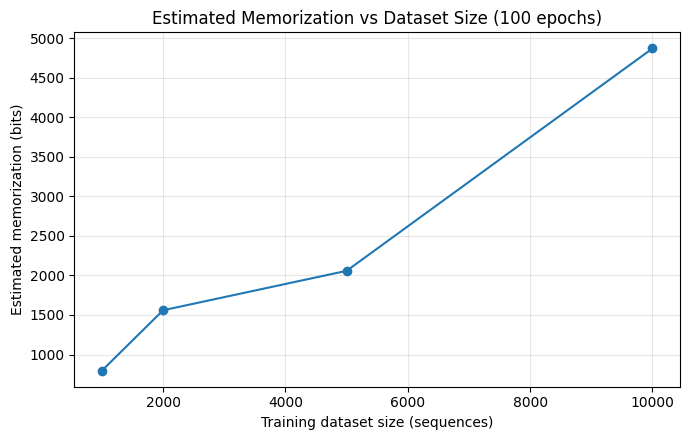

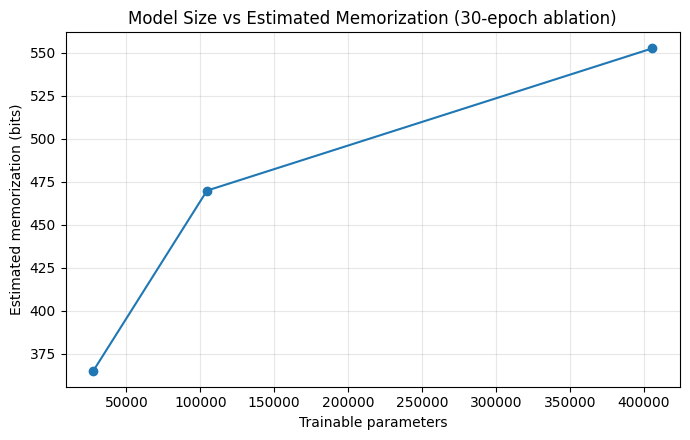

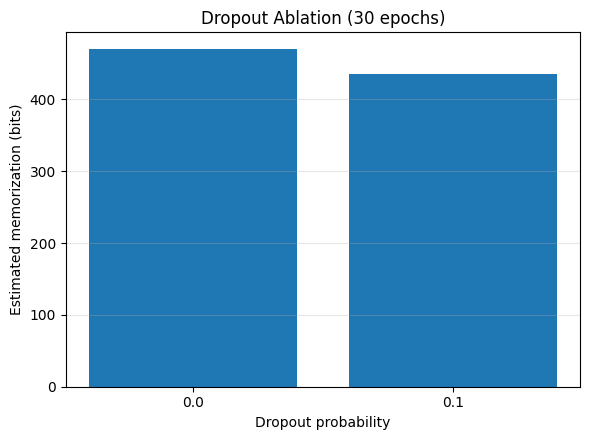

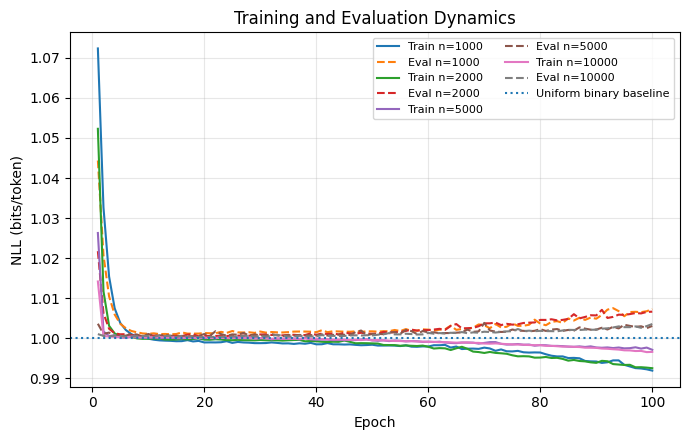

Figures saved in: /content/experiment_outputs/figures


In [12]:
# Figure 1: dataset-size trend
plt.figure(figsize=(7, 4.5))
plt.plot(main_df["dataset_size"], main_df["train_memorization_bits"], marker="o")
plt.xlabel("Training dataset size (sequences)")
plt.ylabel("Estimated memorization (bits)")
plt.title("Estimated Memorization vs Dataset Size (100 epochs)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig1_memorization_vs_dataset_size.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 2: model-size comparison
plt.figure(figsize=(7, 4.5))
plt.plot(model_size_df["parameters"], model_size_df["memorization_bits"], marker="o")
plt.xlabel("Trainable parameters")
plt.ylabel("Estimated memorization (bits)")
plt.title("Model Size vs Estimated Memorization (30-epoch ablation)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig2_memorization_vs_model_size.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 3: dropout ablation
plt.figure(figsize=(6, 4.5))
plt.bar(dropout_df["dropout"].astype(str), dropout_df["memorization_bits"])
plt.xlabel("Dropout probability")
plt.ylabel("Estimated memorization (bits)")
plt.title("Dropout Ablation (30 epochs)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig3_dropout_ablation.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 4: main training/evaluation dynamics, measured at every epoch
plt.figure(figsize=(7, 4.5))
for size, group in main_history_df.groupby("dataset_size"):
    group = group.sort_values("epoch")
    plt.plot(group["epoch"], group["train_nll_bits_per_token"], label=f"Train n={size}")
    plt.plot(group["epoch"], group["eval_nll_bits_per_token"], linestyle="--", label=f"Eval n={size}")
plt.axhline(1.0, linestyle=":", label="Uniform binary baseline")
plt.xlabel("Epoch")
plt.ylabel("NLL (bits/token)")
plt.title("Training and Evaluation Dynamics")
plt.legend(fontsize=8, ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig4_training_dynamics.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figures saved in:", FIGURE_DIR)

## 12. Final integrity checks

These checks verify that the result tables contain the expected run counts, measured values are finite, parameter ratios are consistent, and the main sweep completed the requested number of epochs. A passing check is not a proof that the model has reached theoretical capacity; interpret the results within the stated reduced scale.

In [13]:
assert len(main_df) == len(DATASET_SIZES)
assert sorted(main_df["dataset_size"].tolist()) == DATASET_SIZES
assert main_df["epochs_completed"].eq(MAIN_EPOCHS).all()
assert main_df["parameters"].eq(104514).all()
assert np.isfinite(main_df.select_dtypes(include="number").to_numpy()).all()
assert np.allclose(
    main_df["train_bits_per_parameter"],
    main_df["train_memorization_bits"] / main_df["parameters"],
    rtol=1e-6, atol=1e-9
)
assert set(model_size_df["model"]) == {"small", "medium", "large"}
assert set(dropout_df["dropout"]) == {0.0, 0.1}
assert set(seed_df["seed"]) == {123, 456, 789}

print("PASS: main dataset-size run count and sizes")
print("PASS: all main runs completed 100 epochs")
print("PASS: medium-model parameter count")
print("PASS: finite numeric results")
print("PASS: bits-per-parameter arithmetic")
print("PASS: model-size, dropout, and seed result groups")
print("\nFinal main results:")
display(main_df[[
    "dataset_size", "parameters", "epochs_completed",
    "train_mean_nll_bits_per_token", "eval_mean_nll_bits_per_token",
    "train_memorization_bits", "train_bits_per_parameter", "elapsed_seconds"
]])
print("\nNo results have been hardcoded; the tables above are derived from this run.")

PASS: main dataset-size run count and sizes
PASS: all main runs completed 100 epochs
PASS: medium-model parameter count
PASS: finite numeric results
PASS: bits-per-parameter arithmetic
PASS: model-size, dropout, and seed result groups

Final main results:


,dataset_size,parameters,epochs_completed,train_mean_nll_bits_per_token,eval_mean_nll_bits_per_token,train_memorization_bits,train_bits_per_parameter,elapsed_seconds
0,1000,104514,100,0.991275,1.007238,797.039227,0.007626,13.167985
1,2000,104514,100,0.991564,1.006584,1559.703777,0.014923,17.998434
2,5000,104514,100,0.997056,1.003021,2058.112194,0.019692,38.005991
3,10000,104514,100,0.995656,1.003504,4868.552200,0.046583,71.351938



No results have been hardcoded; the tables above are derived from this run.


## 13. Download the experiment outputs

Run this last cell after all experiments and checks finish. It creates a ZIP containing CSVs, configuration metadata, and figures.

In [14]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/experiment_outputs_clean_submission",
    "zip",
    root_dir=str(OUTPUT_DIR)
)
print("Created:", zip_path)
files.download(zip_path)

Created: /content/experiment_outputs_clean_submission.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>